In [1]:
# Suppress warnings for cleaner output
import warnings
warnings.filterwarnings('ignore')

# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

# Deep learning libraries
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

ModuleNotFoundError: No module named 'matplotlib'

In [ ]:
# Load the dataset
# Replace the file name with your downloaded dataset file name
df = pd.read_csv('/content/customer_purchase_ann.csv')

# Display the first five rows
print("First five rows of the dataset:")
print(df.head())

First five rows of the dataset:
   customer_id  age  income_k  browsing_time_minutes  previous_purchases  \
0            1   50     57.84                      4                   1   
1            2   38    105.69                      2                   4   
2            3   42     96.81                     72                   3   
3            4   28     29.58                     39                   4   
4            5   27     21.64                     56                   4   

   discount_percent  purchased  
0                22          0  
1                26          1  
2                36          1  
3                31          0  
4                26          0  


In [ ]:
# Check dataset shape
print("Dataset Shape:", df.shape)

# Check column names
print("Column Names:")
print(df.columns)

# Check data types and missing values
print("\nDataset Information:")
df.info()

# Summary statistics
print("\nDescriptive Statistics:")
print(df.describe())

Dataset Shape: (200, 7)
Column Names:
Index(['customer_id', 'age', 'income_k', 'browsing_time_minutes',
       'previous_purchases', 'discount_percent', 'purchased'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   customer_id            200 non-null    int64  
 1   age                    200 non-null    int64  
 2   income_k               200 non-null    float64
 3   browsing_time_minutes  200 non-null    int64  
 4   previous_purchases     200 non-null    int64  
 5   discount_percent       200 non-null    int64  
 6   purchased              200 non-null    int64  
dtypes: float64(1), int64(6)
memory usage: 11.1 KB

Descriptive Statistics:
       customer_id         age    income_k  browsing_time_minutes  \
count   200.000000  200.000000  200.000000             200.000000   
mea

In [ ]:
# Check missing values
print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
customer_id              0
age                      0
income_k                 0
browsing_time_minutes    0
previous_purchases       0
discount_percent         0
purchased                0
dtype: int64


In [ ]:
# Drop ID column because it is not useful for prediction
X = df.drop(columns=['customer_id', 'purchased'])
y = df['purchased']

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (200, 5)
Shape of y: (200,)


In [ ]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training Feature Shape:", X_train.shape)
print("Testing Feature Shape:", X_test.shape)
print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Feature Shape: (160, 5)
Testing Feature Shape: (40, 5)
Training Target Shape: (160,)
Testing Target Shape: (40,)


In [ ]:
# Standardize input features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully.")

Feature scaling completed successfully.


In [ ]:
print(X_train_scaled)

[[ 3.50927866e-01  3.34807258e-01 -1.36030617e+00 -4.95235640e-01
  -6.45265521e-01]
 [ 6.34148338e-01  1.20318063e+00 -1.36030617e+00  5.61267058e-01
  -7.28795038e-01]
 [-7.39028419e-02  2.64714340e-01  8.15795114e-01  1.61776976e+00
  -5.61736004e-01]
 [ 1.12978416e+00 -1.48890662e+00  6.21500356e-01  5.61267058e-01
   3.57088686e-01]
 [-7.39028419e-02  6.49576379e-01 -2.72255529e-01 -2.31109965e-01
   8.58265790e-01]
 [ 1.20058928e+00 -2.40538774e-01 -1.01057561e+00 -1.28761266e+00
   1.90029652e-01]
 [-9.94369375e-01  9.08855273e-01  1.16552568e+00  1.35364408e+00
   1.02532482e+00]
 [ 1.38512512e-01  1.37906193e+00 -2.72255529e-01  1.08951841e+00
  -8.95854073e-01]
 [ 1.41300464e+00  5.82079495e-01 -5.05409238e-01 -1.02348699e+00
   2.29706173e-02]
 [-8.52759139e-01 -1.28771398e+00  1.24324358e+00 -1.28761266e+00
  -8.12324556e-01]
 [ 8.46563692e-01  3.23449609e-01 -1.47688303e+00 -1.02348699e+00
  -1.44088417e-01]
 [-1.34839497e+00  7.38490543e-01 -1.12715246e+00 -1.28761266e+00

In [ ]:
# Create ANN model
model = Sequential()

# Input layer and first hidden layer
model.add(Dense(units=16, activation='relu', input_dim=X_train_scaled.shape[1]))

# Second hidden layer
model.add(Dense(units=8, activation='relu'))

# Output layer for binary classification
model.add(Dense(units=1, activation='sigmoid'))

# Display model summary
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 241 (964.00 B)

 Trainable params: 241 (964.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Compile the model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("Model compilation completed successfully.")

Model compilation completed successfully.


In [ ]:
# Train the model
history = model.fit(
    X_train_scaled, y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=8,
    verbose=1
)

Epoch 1/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.9609 - loss: 0.1228 - val_accuracy: 0.9375 - val_loss: 0.1670
Epoch 2/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.9609 - loss: 0.1226 - val_accuracy: 0.9375 - val_loss: 0.1722
Epoch 3/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9609 - loss: 0.1207 - val_accuracy: 0.9375 - val_loss: 0.1730
Epoch 4/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9609 - loss: 0.1198 - val_accuracy: 0.9375 - val_loss: 0.1700
Epoch 5/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9609 - loss: 0.1181 - val_accuracy: 0.9375 - val_loss: 0.1711
Epoch 6/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9609 - loss: 0.1168 - val_accuracy: 0.9375 - val_loss: 0.1684
Epoch 7/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9609 - loss: 0.1157 - val_accuracy: 0.9375 - val_loss: 0.1690
Epoch 8/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9609 - loss: 0.1144 - val_accuracy: 0.

In [ ]:
# Predict probabilities
y_pred_prob = model.predict(X_test_scaled)

# Convert probabilities to class labels
y_pred = (y_pred_prob > 0.5).astype(int).ravel()

# Compare actual and predicted values
comparison_df = pd.DataFrame({
    'Actual Value': y_test.values,
    'Predicted Value': y_pred
})

print(comparison_df.head(10))

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
   Actual Value  Predicted Value
0             0                0
1             1                1
2             0                0
3             1                1
4             1                1
5             1                1
6             1                0
7             1                1
8             1                1
9             1                1


In [ ]:
# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.85
Precision: 0.9310344827586207
Recall: 0.8709677419354839
F1 Score: 0.9

Classification Report:
              precision    recall  f1-score   support

           0       0.64      0.78      0.70         9
           1       0.93      0.87      0.90        31

    accuracy                           0.85        40
   macro avg       0.78      0.82      0.80        40
weighted avg       0.86      0.85      0.86        40



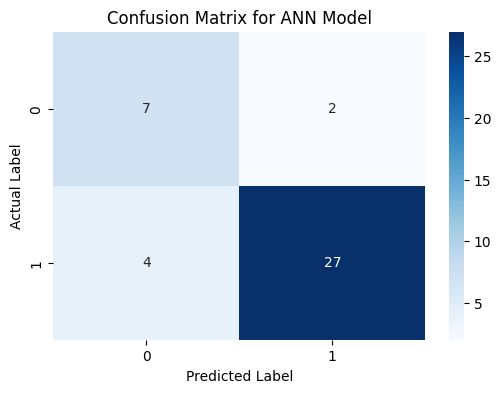

In [ ]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix for ANN Model')
plt.show()

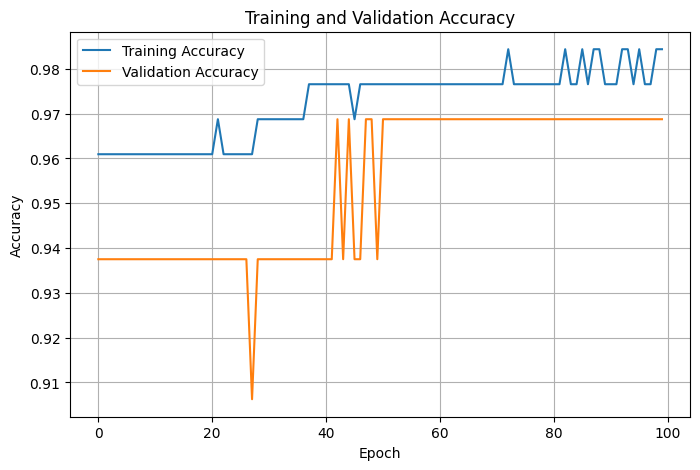

In [ ]:
# Plot training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.grid(True)
plt.show()

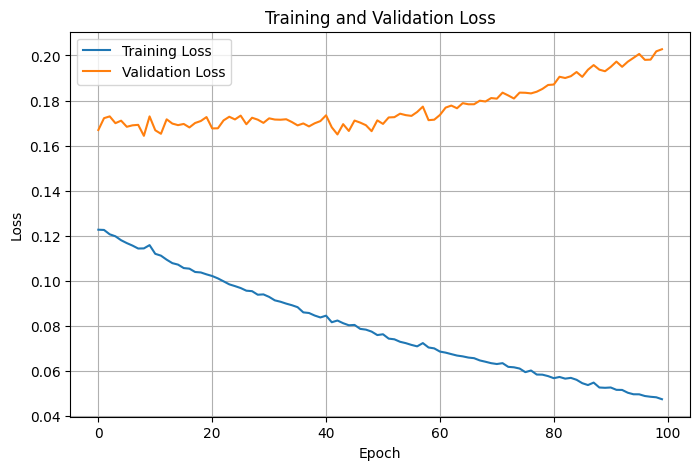

In [ ]:
# Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.grid(True)
plt.show()